# Notebook 04 — Ensemble Models and Hyperparameter Tuning

This notebook adds two ensembles (Random Forest and Gradient Boosting), compares all six models, tunes the two best with `GridSearchCV`, selects the final model, chooses its decision threshold and saves it. Every number comes from cross-validation on the 36,168 training rows; the test set is not used. Run the notebooks in the order 01 → 05 and execute all cells from the top (*Restart* → *Run All*).

## 1. Setup

This section imports the libraries and project modules, recreates the split and loads the core-model results of Notebook 03.

In [1]:
# Make the project's src/ package importable (notebooks live in notebooks/)
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

# Hide FutureWarnings from libraries so that the outputs stay readable
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.metrics import precision_recall_curve
from sklearn.model_selection import cross_validate, learning_curve

# Project modules: figure style, paths, models, tuning and evaluation helpers
from src.plot_style import apply_style, BLUE, ORANGE, GREY
from src.config import FIGURES_DIR, RESULTS_DIR
from src.data_loader import load_raw_data
from src.preprocessing import split_data, build_model_pipeline
from src.train_models import (CV, SCORING, PARAM_GRIDS, get_baseline_and_core_models, get_ensemble_models,
                              cross_validate_models, tune_model, tuning_results_table, best_params_clean,
                              out_of_fold_scores, save_final_model)
from src.evaluate import format_cv_table, find_best_threshold, classification_metrics

apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Same split as before; X_test / y_test are NOT used in this notebook
df = load_raw_data()
X_train, X_test, y_train, y_test = split_data(df)
cv_core = pd.read_csv(RESULTS_DIR / "cv_results_core.csv")   # results of Notebook 03

## 2. Ensemble Models

This section cross-validates the two ensembles with default settings, using the same folds as the core models.

| Model | How it works | Why suitable | Weakness |
|---|---|---|---|
| **Random Forest** (bagging) | Many deep trees on bootstrap samples and random feature subsets; votes are averaged | Averaging decorrelated trees **reduces variance**; robust to outliers; no scaling needed | Less interpretable; large memory footprint |
| **Gradient Boosting** (boosting) | Shallow trees added one after another, each fitting the errors of the current ensemble | Sequential error correction **reduces bias**; strong on tabular data | Many hyperparameters; slower, sequential training; can over-fit with many deep trees |

In [2]:
# 5-fold CV of the two ensembles, then combine with the four earlier models
ensembles = get_ensemble_models()
cv_ens = cross_validate_models(ensembles, X_train, y_train)
cv_all = pd.concat([cv_core, cv_ens], ignore_index=True)
cv_all.to_csv(RESULTS_DIR / "cv_results_all_models.csv", index=False)

Random Forest             ROC-AUC = 0.7779 +/- 0.0054   (8 s)


Gradient Boosting         ROC-AUC = 0.7916 +/- 0.0037   (8 s)


## 3. Comparison of All Six Models

This section compares all six models on the same folds and metrics.

In [3]:
# Mean +/- std of every metric, best ROC-AUC first
table_all = format_cv_table(cv_all).sort_values("roc_auc", ascending=False).reset_index(drop=True)
table_all

,Model,roc_auc,average_precision,f1,precision,recall,accuracy
0,Gradient Boosting,0.792 ± 0.004,0.439 ± 0.011,0.312 ± 0.013,0.654 ± 0.029,0.205 ± 0.010,0.894 ± 0.002
1,Random Forest,0.778 ± 0.005,0.404 ± 0.020,0.427 ± 0.025,0.467 ± 0.022,0.394 ± 0.028,0.877 ± 0.004
2,Logistic Regression,0.764 ± 0.003,0.398 ± 0.007,0.373 ± 0.003,0.266 ± 0.004,0.623 ± 0.010,0.755 ± 0.005
3,K-Nearest Neighbors,0.692 ± 0.008,0.283 ± 0.011,0.299 ± 0.022,0.537 ± 0.031,0.208 ± 0.017,0.886 ± 0.003
4,Decision Tree,0.605 ± 0.006,0.172 ± 0.004,0.301 ± 0.009,0.298 ± 0.008,0.304 ± 0.011,0.835 ± 0.002
5,Dummy (majority class),0.500 ± 0.000,0.117 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.883 ± 0.000


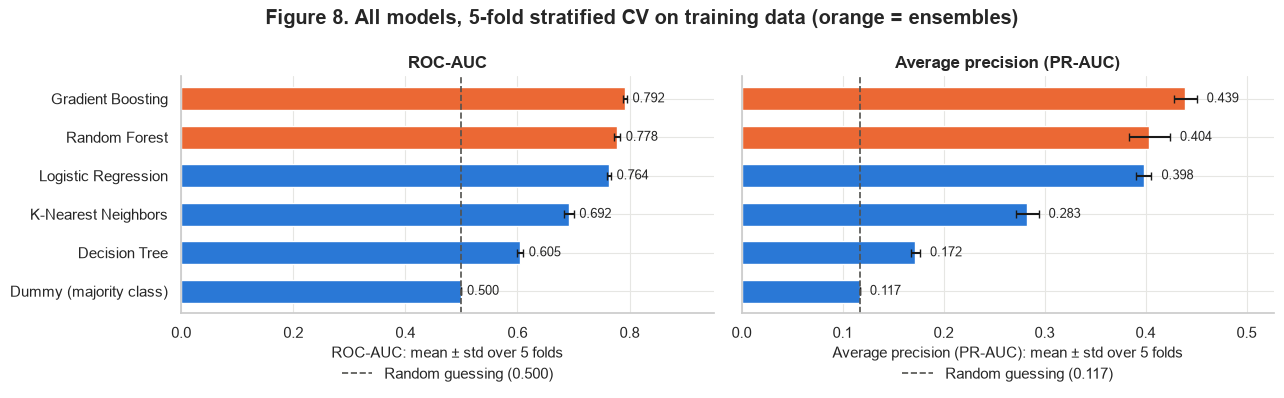

In [4]:
# Figure 8: ROC-AUC and average precision of all models side by side (orange = ensembles)
order = cv_all.sort_values("roc_auc_mean")["model"]
plot_df = cv_all.set_index("model").loc[order]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, metric, title, ref in [
        (axes[0], "roc_auc", "ROC-AUC", 0.5),
        (axes[1], "average_precision", "Average precision (PR-AUC)", y_train.mean())]:
    colors = [ORANGE if m in ensembles else BLUE for m in plot_df.index]
    ax.barh(plot_df.index, plot_df[f"{metric}_mean"], xerr=plot_df[f"{metric}_std"],
            color=colors, height=0.6, capsize=3)
    for i, (m, s) in enumerate(zip(plot_df[f"{metric}_mean"], plot_df[f"{metric}_std"])):
        ax.text(m + s + 0.01, i, f"{m:.3f}", va="center", fontsize=9)
    ax.axvline(ref, ls="--", color=GREY, lw=1.2, label=f"Random guessing ({ref:.3f})")
    ax.set_title(title)
    ax.set_xlabel(f"{title}: mean ± std over 5 folds")
    ax.set_xlim(0, max(plot_df[f"{metric}_mean"]) * 1.2)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17))
axes[0].set_ylabel("")
fig.suptitle("Figure 8. All models, 5-fold stratified CV on training data (orange = ensembles)", fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig08_all_models_cv.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
# Training vs validation scores and fit time of every model
pd.DataFrame({
    "Model": cv_all["model"],
    "Train ROC-AUC": cv_all["train_roc_auc_mean"].round(3),
    "Validation ROC-AUC": cv_all["roc_auc_mean"].round(3),
    "Gap": (cv_all["train_roc_auc_mean"] - cv_all["roc_auc_mean"]).round(3),
    "Fit time per fold (s)": cv_all["fit_time_s"].round(1),
})

,Model,Train ROC-AUC,Validation ROC-AUC,Gap,Fit time per fold (s)
0,Dummy (majority class),0.500,0.500,0.000,0.3
1,Logistic Regression,0.769,0.764,0.005,0.4
2,Decision Tree,1.000,0.605,0.395,0.5
3,K-Nearest Neighbors,0.919,0.692,0.227,0.3
4,Random Forest,1.000,0.778,0.222,2.7
5,Gradient Boosting,0.807,0.792,0.015,5.5


**Interpretation (Figure 8 and tables).**
* **Gradient Boosting** is the best model on both threshold-free metrics (ROC-AUC **0.792 ± 0.004**, average precision **0.439**), ahead of Random Forest (0.778) and Logistic Regression (0.764).
* Its low F1 (0.312) at threshold 0.5 only reflects that it has no class weights, so its probabilities rarely exceed 0.5; this is why models are ranked by ROC-AUC and a threshold is chosen in Section 6.
* The default **Random Forest** still memorises the data (training 1.000 vs validation 0.778), but averaging trees improves massively on a single tree (0.605 → 0.778): bagging reduces variance.
* **Gradient Boosting** has a small gap (0.807 vs 0.792): shallow trees keep variance low and boosting reduces bias.

## 4. Hyperparameter Tuning of the Two Best Models

This section tunes the two best non-baseline models with `GridSearchCV` on the training data only (same 5 folds, all six metrics, `refit="roc_auc"`). The grids are defined in `src/train_models.py` (`PARAM_GRIDS`).

In [6]:
# Select the two best non-baseline models by mean CV ROC-AUC and show their grids
to_tune = (cv_all[~cv_all["model"].str.startswith("Dummy")]
           .sort_values("roc_auc_mean", ascending=False)["model"].head(2).tolist())
print("Models selected for tuning:", to_tune)
for name in to_tune:
    n_comb = int(np.prod([len(v) for v in PARAM_GRIDS[name].values()]))
    print(f"\n{name}: {n_comb} combinations x 5 folds = {n_comb * 5} fits")
    for p, values in PARAM_GRIDS[name].items():
        print(f"   {p.replace('model__', ''):<18} {values}")

Models selected for tuning: ['Gradient Boosting', 'Random Forest']

Gradient Boosting: 36 combinations x 5 folds = 180 fits
   n_estimators       [100, 200, 300]
   learning_rate      [0.05, 0.1]
   max_depth          [3, 4, 5]
   subsample          [0.8, 1.0]

Random Forest: 36 combinations x 5 folds = 180 fits
   n_estimators       [200, 400]
   max_depth          [10, 20, None]
   min_samples_leaf   [1, 5, 10]
   max_features       ['sqrt', 0.3]


In [7]:
# Run the grid searches (about 15 minutes in total; uses all CPU cores)
all_models = {**get_baseline_and_core_models(), **ensembles}
searches = {name: tune_model(name, all_models[name], X_train, y_train) for name in to_tune}

Gradient Boosting: 36 combinations in 538 s -> best CV ROC-AUC = 0.7995


Random Forest: 36 combinations in 254 s -> best CV ROC-AUC = 0.7947


In [8]:
# Safety check: `searches` is created in Section 4 (grid search); this only fails if cells are run out of order
if "searches" not in globals():
    raise RuntimeError("`searches` is not defined yet. Please run the notebook from the top "
                       "(VS Code: 'Restart' then 'Run All'); `searches` is created in Section 4 (grid search).")

# Best parameters and the 8 best combinations of each search
for name, search in searches.items():
    print(f"=== {name}: best parameters = {best_params_clean(search)}")
    tbl = tuning_results_table(search, top=8)
    tbl["params"] = tbl["params"].apply(lambda d: {k.replace("model__", ""): v for k, v in d.items()})
    tbl.to_csv(RESULTS_DIR / f"tuning_top_{name.replace(' ', '_').lower()}.csv", index=False)
    display(tbl.round(4))

=== Gradient Boosting: best parameters = {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 300, 'subsample': 0.8}


,params,mean_test_roc_auc,std_test_roc_auc,mean_train_roc_auc,mean_test_average_precision,mean_test_f1
0,"{'learning_rate': 0.05, 'max_depth': 5, 'n_est...",0.7995,0.0025,0.8622,0.4485,0.3597
1,"{'learning_rate': 0.05, 'max_depth': 5, 'n_est...",0.7993,0.0034,0.8441,0.4503,0.3454
2,"{'learning_rate': 0.05, 'max_depth': 4, 'n_est...",0.7986,0.0040,0.8356,0.4493,0.3518
3,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti...",0.7981,0.0046,0.8430,0.4493,0.3534
4,"{'learning_rate': 0.1, 'max_depth': 4, 'n_esti...",0.7980,0.0034,0.8606,0.4450,0.3621
5,"{'learning_rate': 0.1, 'max_depth': 4, 'n_esti...",0.7977,0.0031,0.8433,0.4433,0.3487
6,"{'learning_rate': 0.1, 'max_depth': 4, 'n_esti...",0.7973,0.0023,0.8589,0.4413,0.3572
7,"{'learning_rate': 0.1, 'max_depth': 4, 'n_esti...",0.7972,0.0038,0.8425,0.4455,0.3569


=== Random Forest: best parameters = {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 400}


,params,mean_test_roc_auc,std_test_roc_auc,mean_train_roc_auc,mean_test_average_precision,mean_test_f1
0,"{'max_depth': 20, 'max_features': 'sqrt', 'min...",0.7947,0.0035,0.9402,0.4419,0.4542
1,"{'max_depth': 20, 'max_features': 'sqrt', 'min...",0.7942,0.0037,0.9401,0.4425,0.4553
2,"{'max_depth': 20, 'max_features': 'sqrt', 'min...",0.7941,0.0043,0.9026,0.4406,0.4439
3,"{'max_depth': 20, 'max_features': 0.3, 'min_sa...",0.7941,0.0041,0.9369,0.4417,0.4527
4,"{'max_depth': 20, 'max_features': 'sqrt', 'min...",0.7941,0.0046,0.9024,0.4399,0.4427
5,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.7938,0.0035,0.9075,0.4391,0.4447
6,"{'max_depth': 20, 'max_features': 0.3, 'min_sa...",0.7938,0.0045,0.9366,0.4411,0.4546
7,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.7937,0.0043,0.9507,0.4420,0.4583


### 4.1 Default vs Tuned

This section compares the default and tuned versions of both models on the same CV metrics.

In [9]:
# Safety check: `searches` is created in Section 4 (grid search); this only fails if cells are run out of order
if "searches" not in globals():
    raise RuntimeError("`searches` is not defined yet. Please run the notebook from the top "
                       "(VS Code: 'Restart' then 'Run All'); `searches` is created in Section 4 (grid search).")

# One row per model and version: default results (Section 3) vs best grid-search result
rows = []
for name, search in searches.items():
    default = cv_all.set_index("model").loc[name]
    tuned = search.cv_results_
    i = search.best_index_                             # row of the best combination
    rows.append({"Model": name, "Version": "default",
                 **{m: default[f"{m}_mean"] for m in SCORING},
                 "roc_auc_std": default["roc_auc_std"], "train_roc_auc": default["train_roc_auc_mean"]})
    rows.append({"Model": name, "Version": "tuned",
                 **{m: tuned[f"mean_test_{m}"][i] for m in SCORING},
                 "roc_auc_std": tuned["std_test_roc_auc"][i], "train_roc_auc": tuned["mean_train_roc_auc"][i]})
default_vs_tuned = pd.DataFrame(rows)
default_vs_tuned.to_csv(RESULTS_DIR / "default_vs_tuned.csv", index=False)
default_vs_tuned.round(4)

,Model,Version,roc_auc,average_precision,f1,precision,recall,accuracy,roc_auc_std,train_roc_auc
0,Gradient Boosting,default,0.7916,0.4393,0.3121,0.6541,0.2052,0.8943,0.0037,0.8070
1,Gradient Boosting,tuned,0.7995,0.4485,0.3597,0.6099,0.2553,0.8938,0.0025,0.8622
2,Random Forest,default,0.7779,0.4038,0.4269,0.4669,0.3935,0.8765,0.0054,1.0000
3,Random Forest,tuned,0.7947,0.4419,0.4542,0.3722,0.5831,0.8360,0.0035,0.9402


**Interpretation.**
* **Gradient Boosting** improves from 0.7916 to **0.7995** ROC-AUC with `learning_rate=0.05, max_depth=5, n_estimators=300, subsample=0.8` (deeper trees capture interactions, a smaller learning rate with more trees learns more carefully, and subsampling reduces variance).
* **Random Forest** improves from 0.7779 to **0.7947** with `max_depth=20, min_samples_leaf=5, max_features="sqrt", n_estimators=400`; limiting depth and leaf size is regularisation (training ROC-AUC falls from 1.000 to 0.940 while validation rises).
* The 8 best combinations of each model lie within 0.0023 of each other, so the result is not sensitive to the exact choice and the search did not over-fit the validation folds.

## 5. Final Model Selection

This section applies the rule fixed before testing: the final model is the tuned model with the highest mean CV ROC-AUC.

In [10]:
# Safety check: `searches` is created in Section 4 (grid search); this only fails if cells are run out of order
if "searches" not in globals():
    raise RuntimeError("`searches` is not defined yet. Please run the notebook from the top "
                       "(VS Code: 'Restart' then 'Run All'); `searches` is created in Section 4 (grid search).")

# Pick the tuned model with the best mean CV ROC-AUC (already re-fitted on the full training set)
final_name = max(searches, key=lambda n: searches[n].best_score_)
final_search = searches[final_name]
final_model = final_search.best_estimator_
i = final_search.best_index_

# CV summary of the selected configuration (stored with the model)
cv_summary = {m: float(final_search.cv_results_[f"mean_test_{m}"][i]) for m in SCORING}
cv_summary["roc_auc_std"] = float(final_search.cv_results_["std_test_roc_auc"][i])
cv_summary["train_roc_auc"] = float(final_search.cv_results_["mean_train_roc_auc"][i])
print("Final model:", final_name)
print("Best parameters:", best_params_clean(final_search))
pd.Series(cv_summary).round(4)

Final model: Gradient Boosting
Best parameters: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 300, 'subsample': 0.8}


roc_auc              0.7995
average_precision    0.4485
f1                   0.3597
precision            0.6099
recall               0.2553
accuracy             0.8938
roc_auc_std          0.0025
train_roc_auc        0.8622
dtype: float64

## 6. Decision Threshold

This section chooses the probability cut-off that maximises F1 on **out-of-fold** training predictions (`cross_val_predict`: each row is scored by a model that did not see it), so the test set is not involved.

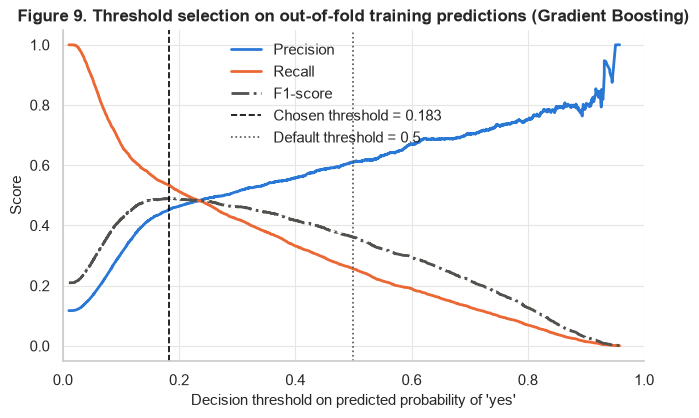

,threshold = 0.5,threshold = 0.183
accuracy,0.8938,0.8701
precision,0.6102,0.4530
recall,0.2553,0.5339
f1,0.3599,0.4901
roc_auc,0.7994,0.7994
average_precision,0.4467,0.4467


In [11]:
# Safety check: `final_model` is created in Section 5 (Final Model Selection); this only fails if cells are run out of order
if "final_model" not in globals():
    raise RuntimeError("`final_model` is not defined yet. Please run the notebook from the top "
                       "(VS Code: 'Restart' then 'Run All'); `final_model` is created in Section 5 (Final Model Selection).")

# Out-of-fold probabilities on the training set and the F1-maximising threshold
oof = out_of_fold_scores(final_model, X_train, y_train)
threshold, best_f1 = find_best_threshold(y_train, oof)

# Figure 9: precision, recall and F1 for every possible threshold
prec, rec, thr = precision_recall_curve(y_train, oof)
f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.plot(thr, prec[:-1], color=BLUE, lw=2, label="Precision")
ax.plot(thr, rec[:-1], color=ORANGE, lw=2, label="Recall")
ax.plot(thr, f1, color=GREY, lw=2, ls="-.", label="F1-score")
ax.axvline(threshold, ls="--", color="black", lw=1.2, label=f"Chosen threshold = {threshold:.3f}")
ax.axvline(0.5, ls=":", color=GREY, lw=1.2, label="Default threshold = 0.5")
ax.set_title(f"Figure 9. Threshold selection on out-of-fold training predictions ({final_name})")
ax.set_xlabel("Decision threshold on predicted probability of 'yes'")
ax.set_ylabel("Score")
ax.set_xlim(0, 1)
ax.legend(loc="upper center", bbox_to_anchor=(0.47, 1.0))
fig.savefig(FIGURES_DIR / "fig09_threshold_selection.png", dpi=150, bbox_inches="tight")
plt.show()

# Out-of-fold metrics at the default and at the chosen threshold
oof_metrics = pd.DataFrame({
    "threshold = 0.5": classification_metrics(y_train, (oof >= 0.5).astype(int), oof),
    f"threshold = {threshold:.3f}": classification_metrics(y_train, (oof >= threshold).astype(int), oof),
}).round(4)
oof_metrics

**Interpretation (Figure 9).** The F1-maximising threshold is **0.183**. Compared with 0.5, recall doubles (0.255 → 0.534), precision drops (0.61 → 0.45) and F1 rises from 0.360 to **0.490**; ROC-AUC and average precision are unchanged because they do not depend on the threshold.

## 7. Learning Curve of the Final Model

This section trains the final configuration on growing portions of the training data (5-fold CV each time) and reports the scores as a table to check bias and variance.

In [12]:
# Safety check: `final_model` is created in Section 5 (Final Model Selection); this only fails if cells are run out of order
if "final_model" not in globals():
    raise RuntimeError("`final_model` is not defined yet. Please run the notebook from the top "
                       "(VS Code: 'Restart' then 'Run All'); `final_model` is created in Section 5 (Final Model Selection).")

# Training and validation ROC-AUC for 10 %, 25 %, 50 %, 75 % and 100 % of the training folds
sizes, lc_train, lc_val = learning_curve(
    final_model, X_train, y_train, train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0],
    cv=CV, scoring="roc_auc", n_jobs=-1, shuffle=True, random_state=42)

# Mean training and validation ROC-AUC and their gap for each training size
pd.DataFrame({"train_rows": sizes, "train_auc": lc_train.mean(axis=1),
              "val_auc": lc_val.mean(axis=1), "gap": lc_train.mean(axis=1) - lc_val.mean(axis=1)}).round(4)

,train_rows,train_auc,val_auc,gap
0,2893,0.9985,0.7542,0.2443
1,7233,0.9574,0.7762,0.1812
2,14467,0.9044,0.7903,0.1141
3,21700,0.8786,0.7965,0.0822
4,28934,0.8617,0.7995,0.0622


**Interpretation.** With few rows the model nearly memorises the data (training 0.999 vs validation 0.754); as data grow the gap shrinks from 0.244 to 0.062 and the validation score rises slowly to 0.800. The plateau near 0.80 suggests that the remaining error is mainly bias due to missing information in the pre-call features.

## 8. Secondary Experiment: Including `duration`

This section re-trains the same tuned configuration with `duration` added, **for discussion only**: it is cross-validated on the training data and never used for selection or deployment.

In [13]:
# Safety check: `final_model` is created in Section 5 (Final Model Selection); this only fails if cells are run out of order
if "final_model" not in globals():
    raise RuntimeError("`final_model` is not defined yet. Please run the notebook from the top "
                       "(VS Code: 'Restart' then 'Run All'); `final_model` is created in Section 5 (Final Model Selection).")

# Same training rows, but with duration as an additional numeric feature
Xd_train, _, yd_train, _ = split_data(df, include_duration=True)
assert Xd_train.index.equals(X_train.index)

# Cross-validate the tuned model configuration with duration
with_duration = build_model_pipeline(clone(final_model.named_steps["model"]), include_duration=True)
res = cross_validate(with_duration, Xd_train, yd_train, cv=CV, scoring=SCORING, n_jobs=-1)
duration_exp = pd.DataFrame({
    "without duration (realistic, final)": {m: cv_summary[m] for m in SCORING},
    "with duration (leakage, NOT usable)": {m: float(np.mean(res[f"test_{m}"])) for m in SCORING},
}).round(4)
duration_exp.to_csv(RESULTS_DIR / "duration_experiment.csv")
duration_exp

,"without duration (realistic, final)","with duration (leakage, NOT usable)"
roc_auc,0.7995,0.9349
average_precision,0.4485,0.6215
f1,0.3597,0.5468
precision,0.6099,0.6450
recall,0.2553,0.4748
accuracy,0.8938,0.9080


**Interpretation.** Adding `duration` raises the CV ROC-AUC from **0.800 to 0.935** and F1 from 0.36 to 0.55 (threshold 0.5). This jump is what leakage looks like: long calls are a consequence of an interested client, and the duration is unknown before dialling, so the decision to exclude it is confirmed.

## 9. Save the Final Model

This section saves the fitted pipeline and its metadata (threshold, parameters, valid input values) for Notebook 05 and the Streamlit app.

In [14]:
# Safety check: `threshold` is created in Section 6 (Decision Threshold); this only fails if cells are run out of order
if "threshold" not in globals():
    raise RuntimeError("`threshold` is not defined yet. Please run the notebook from the top "
                       "(VS Code: 'Restart' then 'Run All'); `threshold` is created in Section 6 (Decision Threshold).")

# models/final_model.joblib + models/model_metadata.json
save_final_model(final_model, final_name, best_params_clean(final_search), threshold, cv_summary, X_train)

# Selection details used by the report
selection = {"final_model": final_name, "tuned_models": to_tune,
             "best_params": {n: {k: str(v) for k, v in best_params_clean(s).items()} for n, s in searches.items()},
             "best_cv_roc_auc": {n: float(s.best_score_) for n, s in searches.items()},
             "threshold": threshold, "oof_f1_at_threshold": best_f1, "cv_summary": cv_summary,
             "oof_metrics": oof_metrics.to_dict()}
(RESULTS_DIR / "final_model_selection.json").write_text(json.dumps(selection, indent=2))
print(json.dumps(selection["best_cv_roc_auc"], indent=2))

Saved model to models/final_model.joblib
{
  "Gradient Boosting": 0.7995126827046592,
  "Random Forest": 0.7947274445375843
}


## 10. Summary

* **Ensembles:** Gradient Boosting was the best of the six models with default settings (CV ROC-AUC 0.792), followed by Random Forest (0.778).
* **Tuning:** tuned Gradient Boosting reached **0.7995 ± 0.0025** (tuned Random Forest 0.7947) and was selected.
* **Threshold:** 0.183, chosen on out-of-fold training predictions (F1 0.49).
* **Leakage check:** including `duration` would inflate ROC-AUC to 0.935.
* **Saved:** `models/final_model.joblib` and `models/model_metadata.json`; Notebook 05 evaluates the model once on the test set.